# Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    classification_report
)

# Load the Iris dataset

In [2]:
iris = load_iris()

X = iris.data
y = iris.target

print("Dataset Shape:", X.shape)
print("Features:", iris.feature_names)
print("Target Classes:", iris.target_names)

Dataset Shape: (150, 4)
Features: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Target Classes: ['setosa' 'versicolor' 'virginica']


# Display The Dataset

In [3]:
df = pd.DataFrame(
    X,
    columns=iris.feature_names
)

df["Target"] = y

df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


# Split the dataset

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (120, 4)
Testing Data: (30, 4)


# Logistic Regression

In [5]:
logistic_model = LogisticRegression(
    max_iter=200
)

# Decision Tree

In [6]:
tree_model = DecisionTreeClassifier(
    random_state=42
)

# KNN

In [7]:
knn_model = KNeighborsClassifier(
    n_neighbors=5
)

# Train all models

In [8]:
logistic_model.fit(X_train, y_train)

tree_model.fit(X_train, y_train)

knn_model.fit(X_train, y_train)

print("All models trained successfully!")

All models trained successfully!


# Make predictions

In [9]:
logistic_pred = logistic_model.predict(X_test)

tree_pred = tree_model.predict(X_test)

knn_pred = knn_model.predict(X_test)

# Calculate Accuracy, Precision and Recall

In [10]:
def evaluate_model(name, y_test, y_pred):

    accuracy = accuracy_score(
        y_test,
        y_pred
    )

    precision = precision_score(
        y_test,
        y_pred,
        average="weighted"
    )

    recall = recall_score(
        y_test,
        y_pred,
        average="weighted"
    )

    print("\n", name)
    print("Accuracy :", accuracy)
    print("Precision:", precision)
    print("Recall   :", recall)

# Evaluate Logistic Regression

In [11]:
evaluate_model(
    "Logistic Regression",
    y_test,
    logistic_pred
)


 Logistic Regression
Accuracy : 0.9666666666666667
Precision: 0.9696969696969696
Recall   : 0.9666666666666667


# Evaluate Decision Tree

In [12]:
evaluate_model(
    "Decision Tree",
    y_test,
    tree_pred
)


 Decision Tree
Accuracy : 0.9333333333333333
Precision: 0.9333333333333333
Recall   : 0.9333333333333333


# Evaluate KNN

In [13]:
evaluate_model(
    "KNN",
    y_test,
    knn_pred
)


 KNN
Accuracy : 1.0
Precision: 1.0
Recall   : 1.0


# Create comparison table

In [14]:
results = []

models = [
    ("Logistic Regression", logistic_pred),
    ("Decision Tree", tree_pred),
    ("KNN", knn_pred)
]

for name, prediction in models:

    accuracy = accuracy_score(
        y_test,
        prediction
    )

    precision = precision_score(
        y_test,
        prediction,
        average="weighted"
    )

    recall = recall_score(
        y_test,
        prediction,
        average="weighted"
    )

    results.append([
        name,
        accuracy,
        precision,
        recall
    ])

results_df = pd.DataFrame(
    results,
    columns=[
        "Algorithm",
        "Accuracy",
        "Precision",
        "Recall"
    ]
)

results_df


,Algorithm,Accuracy,Precision,Recall
0,Logistic Regression,0.966667,0.969697,0.966667
1,Decision Tree,0.933333,0.933333,0.933333
2,KNN,1.000000,1.000000,1.000000


# Convert values into percentage

In [15]:
results_percentage = results_df.copy()

results_percentage[
    ["Accuracy", "Precision", "Recall"]
] = results_percentage[
    ["Accuracy", "Precision", "Recall"]
] * 100

results_percentage

,Algorithm,Accuracy,Precision,Recall
0,Logistic Regression,96.666667,96.969697,96.666667
1,Decision Tree,93.333333,93.333333,93.333333
2,KNN,100.000000,100.000000,100.000000


# Display comparison graph

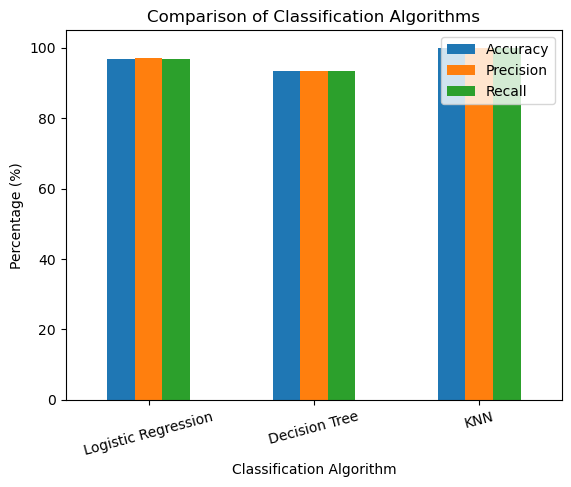

In [16]:
results_percentage.plot(
    x="Algorithm",
    y=["Accuracy", "Precision", "Recall"],
    kind="bar"
)

plt.title(
    "Comparison of Classification Algorithms"
)

plt.ylabel("Percentage (%)")

plt.xlabel("Classification Algorithm")

plt.xticks(rotation=15)

plt.show()

# Classification report

# Logistic Regression

In [17]:
print("Logistic Regression Report")
print(
    classification_report(
        y_test,
        logistic_pred,
        target_names=iris.target_names
    )
)

Logistic Regression Report
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



# Decision Tree

In [18]:
print("Decision Tree Report")
print(
    classification_report(
        y_test,
        tree_pred,
        target_names=iris.target_names
    )
)

Decision Tree Report
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



# KNN

In [19]:
print("KNN Report")
print(
    classification_report(
        y_test,
        knn_pred,
        target_names=iris.target_names
    )
)

KNN Report
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00        10
   virginica       1.00      1.00      1.00        10

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30

